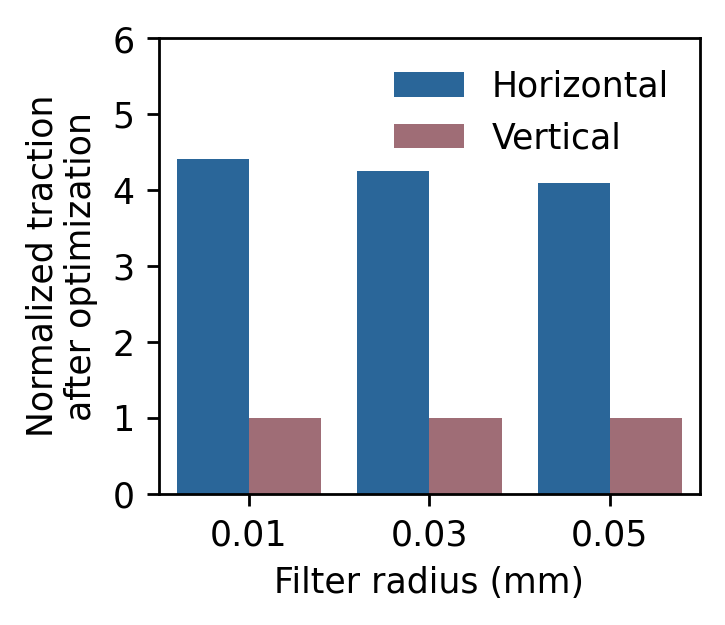

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

thres_paths = {
    0.01: "../../outputs/trapezoid-2026-04-13-16-18-49-radius001/records.csv",
    0.03: "../../outputs/trapezoid-2026-04-13-16-18-42-radius003/records.csv",
    0.05: "../../outputs/trapezoid-2026-04-13-16-18-37-radius005/records.csv",

}

dfs = {
    key: pd.read_csv(val) for key, val in thres_paths.items()
}

dfs_processed = {
    key: pd.DataFrame({"Filter Radius": [key, key], "type": ["Horizontal", "Vertical"], "value": [val["top_x"].values[-1]/val["top_x"].values[0], val["top_y"].values[-1]/val["top_y"].values[0]], "abs_increase": [-(val["top_x"].values[-1]-val["top_x"].values[0]), val["top_y"].values[-1]-val["top_y"].values[0]]}) for key, val in dfs.items()
}

df = pd.concat(dfs_processed.values())

import seaborn as sns

plt.figure(figsize=(3.,2.6), dpi=250)
ax = plt.subplot(111)
sns.barplot(data=df, x="Filter Radius", y="value", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
ax.set_ylim([0, 6])
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False, ncol=1)
ax.set_xlabel("Filter radius (mm)") 
ax.set_ylabel("Normalized reaction\nafter optimization")

# ax = plt.subplot(122)
# sns.barplot(data=df, x="Filter Radius", y="abs_increase", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
# handles, labels = ax.get_legend_handles_labels()
# ax.get_legend().remove()
# ax.legend(handles=handles, labels=labels, title=False, frameon=False, loc="upper right", ncol=2)
# ax.set_xlabel("Filter radius")
# ax.set_ylabel("Increase of tractions (N)\nafter optimizing $c$")
# ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
# ax.set_ylim([-0.8e-3, 2e-3])

plt.tight_layout()
plt.savefig("trapezoid_threshold_traction_diff.pdf", bbox_inches="tight")
plt.show()
plt.close()